In [1]:
from bia_bob import bob
import os
bob.initialize(endpoint="https://chat.ai.e-infra.cz/api/", model="gpt-oss-120b")

c:\ProgramData\miniconda3\envs\bob-env\Lib\site-packages\PIL\Image.py:3452: DecompressionBombWarning: Image size (147083040 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


[[[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 ...

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]]
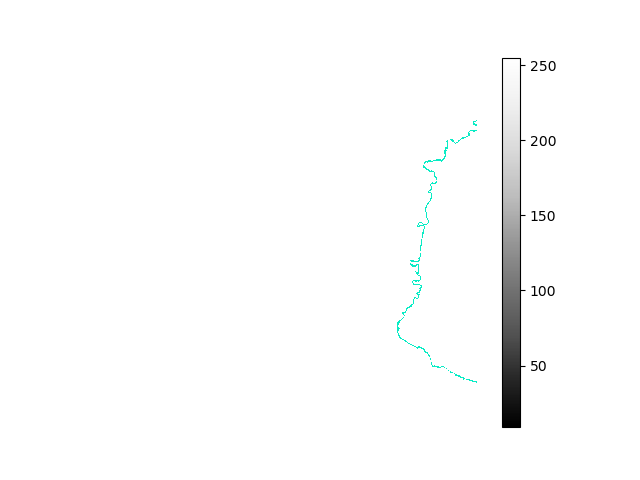
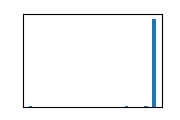

In [2]:
from skimage.io import imread
import stackview
import numpy as np  # np is already available, but importing is harmless

mask_path = "calibrated_BLADDER I K DETAILS-Region 001-41 1-labels.png"

mask = imread(mask_path)
stackview.insight(mask)  # show the mask in stackview

In [ ]:
%bob run erosion and dilation on the mask

I will apply binary erosion and binary dilation to the existing `mask` image, store the results in new variables, and display both processed images.



In [ ]:
%bob convert mask to binary

I will convert the existing `mask` image to a binary image using Otsu’s threshold, store the result in `binary_mask`, and display the binary mask.



In [ ]:
# Create binary mask (foreground = True, background = False)


In [3]:
mask = mask[:, :, 0] < 255
mask.shape

(20952, 7020)

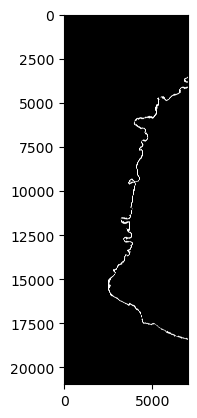

In [57]:
import matplotlib.pyplot as plt

# The error occurs because plt.imshow expects the input array to be of dtype uint8, int16, float32, or float64.
# binary_mask is of dtype bool. Convert it to uint8 before displaying.

plt.imshow(mask.astype(np.uint8), cmap='gray')
plt.show()

c:\ProgramData\miniconda3\envs\bob-env\Lib\site-packages\stackview\_static_view.py:107: RuntimeWarning: Converting input from bool to <class 'numpy.uint8'> for compatibility.
  h, _ = np.histogram(self, bins=num_bins)


[[False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]
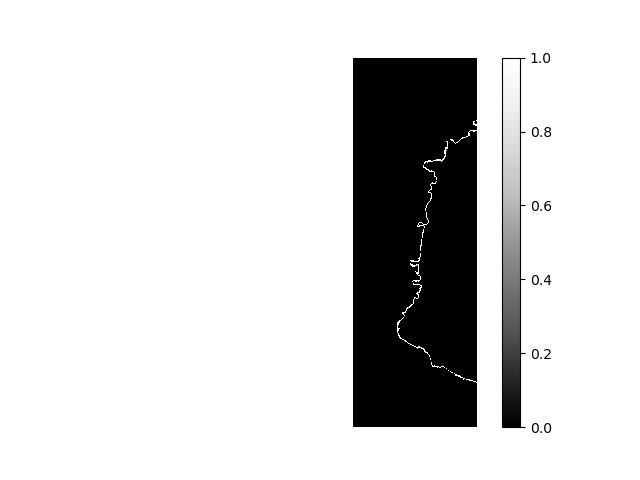
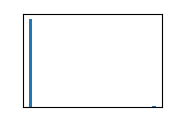

In [4]:
# Imports
from skimage.morphology import binary_erosion, binary_dilation, square, ball

# Perform erosion and dilation without modifying the original mask
eroded_mask = binary_erosion(mask)
dilated_mask = binary_dilation(mask)

stackview.insight(eroded_mask)  # show the dilated mask in stackview
# stackview.insight(eroded_mask.astype(np.uint8))  # show the eroded mask in stackview

c:\ProgramData\miniconda3\envs\bob-env\Lib\site-packages\stackview\_static_view.py:107: RuntimeWarning: Converting input from bool to <class 'numpy.uint8'> for compatibility.
  h, _ = np.histogram(self, bins=num_bins)


[[False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]
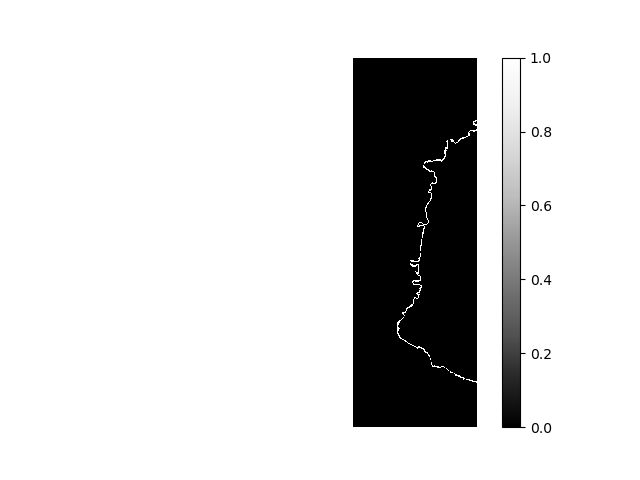
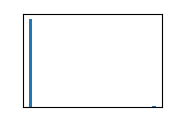

In [59]:
stackview.insight(dilated_mask)

In [ ]:
%bob give me the number of connected elements in the dilated_mask

We will count how many connected components (objects) are present in the already‑available binary image `dilated_mask`.



Number of connected elements in dilated_mask: 6


[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
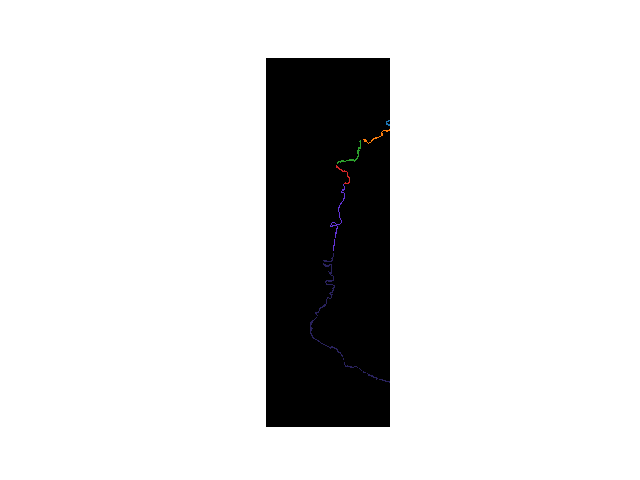

In [5]:
from skimage.measure import label
import stackview

# 1. Label the dilated mask (8‑connectivity for 2‑D, 26‑connectivity for 3‑D is default)
labeled = label(dilated_mask, background=0)

# 2. Count connected components (exclude background)
num_connected = np.max(labeled)   # same as len(np.unique(labeled)) - 1

print(f"Number of connected elements in dilated_mask: {num_connected}")

# 3. (Optional) Visualise the labelled image
stackview.insight(labeled)

c:\ProgramData\miniconda3\envs\bob-env\Lib\site-packages\stackview\_static_view.py:107: RuntimeWarning: Converting input from bool to <class 'numpy.uint8'> for compatibility.
  h, _ = np.histogram(self, bins=num_bins)


[[False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]
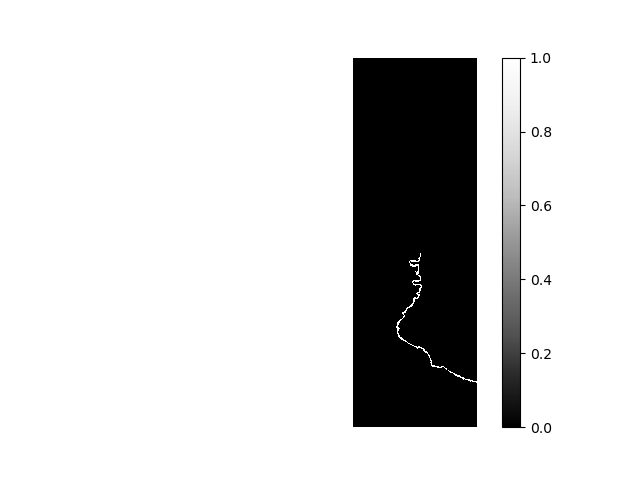
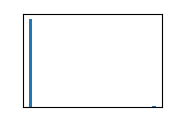

In [ ]:
first_label = labeled == 6
stackview.insight(first_label)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]
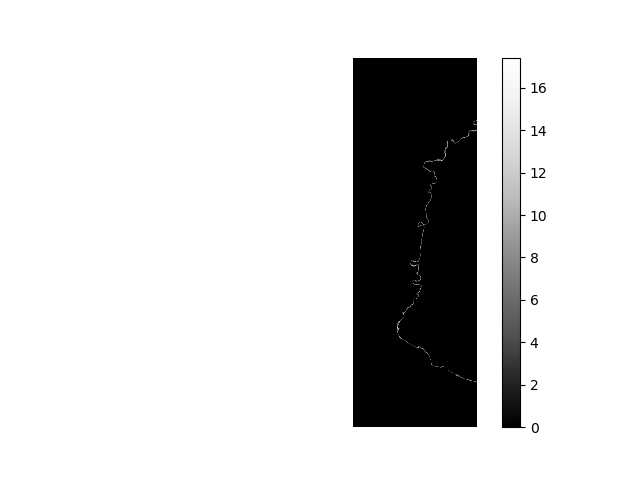
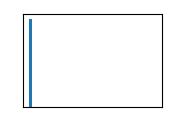

In [6]:
pixel_size = 0.265

import numpy as np
from scipy import ndimage as ndi
# OR: from skimage.morphology import distance_transform_edt as edt

# mask: binary array, True/1 = foreground (or background; see note below)

# Distance to the nearest zero (background) *in real units*
Dist = ndi.distance_transform_edt(mask, sampling=(pixel_size, pixel_size))
# D is in µm (given the sampling above)

stackview.insight(Dist)


In [ ]:
%bob save Dist as a tiff file

Save the NumPy array stored in the variable **Dist** to a TIFF file on disk.



In [7]:
# Choose output path
tiff_path = "Dist.tif"

# Ensure the array is in a write‑able dtype (float32 works for most distance maps)
Dist_to_save = Dist.astype(np.float32)

# Save as TIFF using matplotlib's imsave
plt.imsave(tiff_path, Dist_to_save, cmap='gray')

print(f"Dist saved to {tiff_path}")

NameError: name 'plt' is not defined

In [ ]:
Dist.shape

(2619, 878)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]
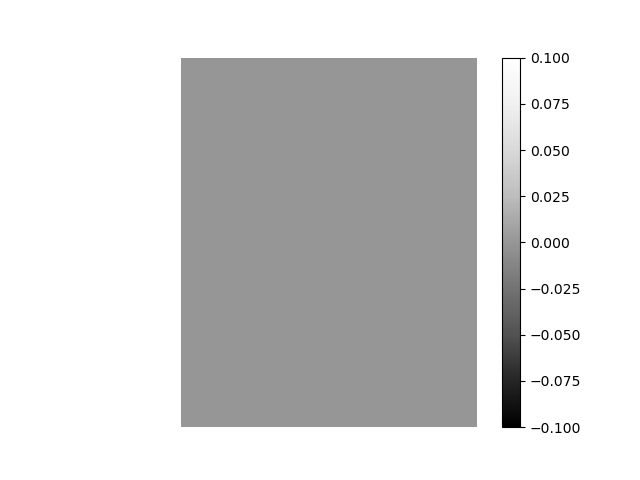
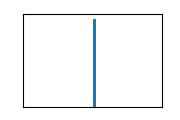

In [8]:
croppedDist = Dist[1000:1500, 400:800]
stackview.insight(croppedDist)

In [ ]:
%bob how do I crop the image to the bounding box of the mask

You want to crop an image (or stack) so that it tightly encloses the non‑zero region of a binary mask. This is done by extracting the mask’s bounding box and applying the same slice to the original image.



c:\ProgramData\miniconda3\envs\bob-env\Lib\site-packages\stackview\_static_view.py:107: RuntimeWarning: Converting input from bool to <class 'numpy.uint8'> for compatibility.
  h, _ = np.histogram(self, bins=num_bins)


[[False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]
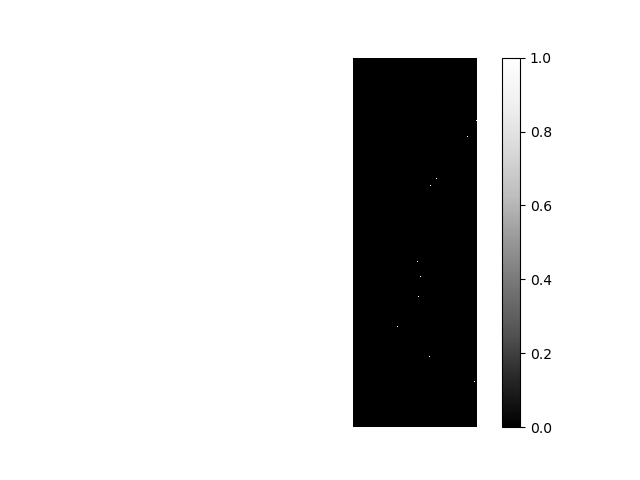
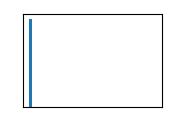

In [9]:
from skimage.morphology import skeletonize
skeleton = skeletonize(mask)
stackview.insight(skeleton)

In [10]:
import numpy as np
from skimage.morphology import skeletonize
from skimage.measure import label
import networkx as nx

# weights for 8-neighborhood: (dr, dc) -> cost
_OFFSETS = [(-1,-1), (-1,0), (-1,1),
            ( 0,-1),          ( 0,1),
            ( 1,-1), ( 1,0),  ( 1,1)]
_WEIGHTS = [np.sqrt(2), 1, np.sqrt(2),
            1,                1,
            np.sqrt(2), 1,    np.sqrt(2)]

def prune_to_longest_path(skel: np.ndarray, keep_per_component=False):
    """
    skel: binary skeleton (True/1 where skeleton pixels are)
    keep_per_component: if True, keeps the longest path within EACH connected component;
                        if False (default), keeps only the single longest path in the whole image.
    Returns a binary mask of the same shape with only the longest path(s) kept.
    """
    skel = skel.astype(bool)
    H, W = skel.shape
    out = np.zeros_like(skel, dtype=bool)

    # label components to handle disconnected skeletons cleanly
    lbl = label(skel, connectivity=2)
    labels = np.unique(lbl)[1:]  # skip background

    def component_longest_path_mask(comp_mask):
        # map (r,c) <-> node id
        coords = np.argwhere(comp_mask)
        id_of = { (r,c): i for i,(r,c) in enumerate(map(tuple, coords)) }
        G = nx.Graph()
        G.add_nodes_from(range(len(coords)))

        for idx,(r,c) in enumerate(coords):
            for (dr,dc), w in zip(_OFFSETS, _WEIGHTS):
                nr, nc = r+dr, c+dc
                if 0 <= nr < H and 0 <= nc < W and comp_mask[nr, nc]:
                    j = id_of[(nr,nc)]
                    if j != idx:
                        G.add_edge(idx, j, weight=w)

        if G.number_of_nodes() == 0:
            return np.zeros_like(comp_mask, dtype=bool)

        # endpoints (degree == 1)
        endpoints = [n for n,deg in G.degree() if deg == 1]

        # choose a start node
        start = endpoints[0] if endpoints else next(iter(G.nodes))

        # 1st sweep: farthest from start
        lengths = nx.single_source_dijkstra_path_length(G, start, weight='weight')
        a = max(lengths, key=lengths.get)

        # 2nd sweep: farthest from a
        lengths2, paths = nx.single_source_dijkstra(G, a, weight='weight')
        b = max(lengths2, key=lengths2.get)

        # retrieve path a->b and rasterize it
        path_nodes = paths[b]
        path_mask = np.zeros_like(comp_mask, dtype=bool)
        for n in path_nodes:
            r, c = coords[n]
            path_mask[r, c] = True
        return path_mask

    if keep_per_component:
        for k in labels:
            comp = (lbl == k)
            out |= component_longest_path_mask(comp)
    else:
        # find the single global longest path across all components
        best_len = -np.inf
        best_mask = None
        for k in labels:
            comp = (lbl == k)
            # build graph and compute path; also compute its length
            tmp_mask = component_longest_path_mask(comp)
            # approximate length as number of pixels along the path with diagonal cost accounted:
            # compute length by summing neighbor steps along the path
            coords = np.argwhere(tmp_mask)
            if coords.size == 0:
                continue
            # quick length via graph again (reuse logic)
            # get endpoints within this path
            # build tiny graph on this path to measure endpoints distance
            # (for robustness, reuse the component graph function)
            path_len = tmp_mask.sum()  # fallback proxy
            if path_len > best_len:
                best_len = path_len
                best_mask = tmp_mask
        out = best_mask if best_mask is not None else out

    return out

# Example usage:
# skel_img = ...  # your binary skeleton
# longest_path = prune_to_longest_path(skel_img, keep_per_component=False)


In [11]:
img_longest = prune_to_longest_path(skeleton, keep_per_component=True)

Number of connected elements in dilated_mask: 6


[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
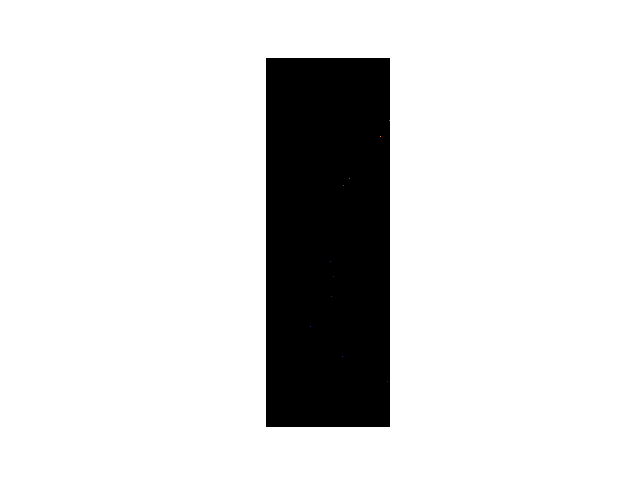

In [14]:
# 1. Label the dilated mask (8‑connectivity for 2‑D, 26‑connectivity for 3‑D is default)
labeled_skeletons = label(img_longest, background=0)

# 2. Count connected components (exclude background)
num_connected = np.max(labeled_skeletons)   # same as len(np.unique(labeled)) - 1

print(f"Number of connected elements in dilated_mask: {num_connected}")

# 3. (Optional) Visualise the labelled image
stackview.insight(labeled_skeletons)

c:\ProgramData\miniconda3\envs\bob-env\Lib\site-packages\stackview\_static_view.py:107: RuntimeWarning: Converting input from bool to <class 'numpy.uint8'> for compatibility.
  h, _ = np.histogram(self, bins=num_bins)


[[False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]
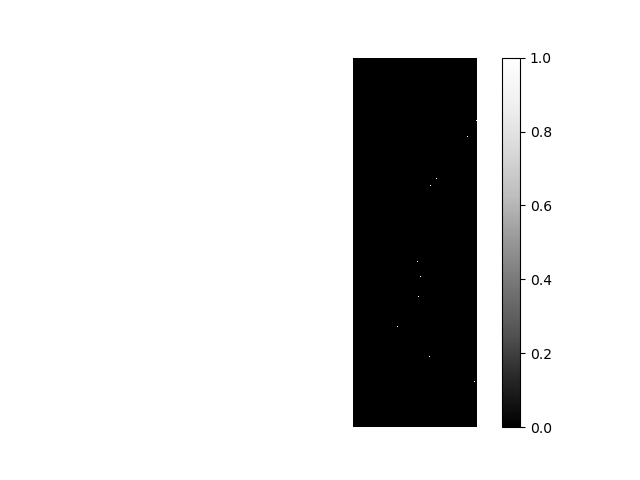
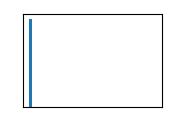

In [12]:
stackview.insight(img_longest)

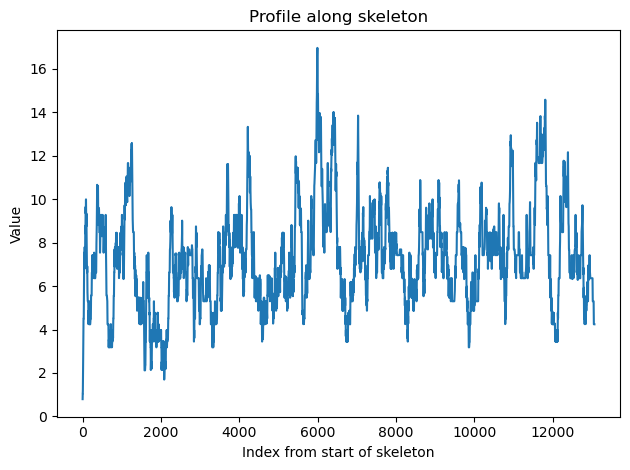

In [13]:
import numpy as np
import networkx as nx
from skimage.measure import label
import matplotlib.pyplot as plt

# 8-neighbourhood offsets + step costs
_OFF = [(-1,-1), (-1,0), (-1,1),
        ( 0,-1),         ( 0,1),
        ( 1,-1), ( 1,0), ( 1,1)]
_W   = [np.sqrt(2),1,np.sqrt(2), 1,1, np.sqrt(2),1,np.sqrt(2)]

def _component_graph(mask):
    """Build a weighted 8-connected graph for this component mask."""
    H, W = mask.shape
    coords = np.argwhere(mask)
    id_of = {tuple(rc): i for i, rc in enumerate(coords)}
    G = nx.Graph()
    G.add_nodes_from(range(len(coords)))
    for i,(r,c) in enumerate(coords):
        for (dr,dc), w in zip(_OFF, _W):
            nr, nc = r+dr, c+dc
            if 0 <= nr < H and 0 <= nc < W and mask[nr, nc]:
                j = id_of[(nr, nc)]
                if j != i:
                    G.add_edge(i, j, weight=w)
    return G, coords

def longest_ordered_path(skel):
    """
    Return the single longest geodesic path across the whole skeleton,
    as an ordered list of (row, col) coordinates from one end to the other.
    """
    skel = skel.astype(bool)
    lbl = label(skel, connectivity=2)
    best_len = -np.inf
    best_path_coords = None

    for k in np.unique(lbl)[1:]:
        comp = (lbl == k)
        G, coords = _component_graph(comp)
        if G.number_of_nodes() == 0:
            continue

        # endpoints = degree 1 (if none -> loop: pick arbitrary start)
        endpoints = [n for n,deg in G.degree() if deg == 1]
        start = endpoints[0] if endpoints else next(iter(G.nodes))

        # two-sweep Dijkstra to find diameter path
        d1 = nx.single_source_dijkstra_path_length(G, start, weight='weight')
        a = max(d1, key=d1.get)
        d2, paths = nx.single_source_dijkstra(G, a, weight='weight')
        b = max(d2, key=d2.get)
        path_nodes = paths[b]
        path_len = d2[b]

        if path_len > best_len:
            best_len = path_len
            best_path_coords = [tuple(coords[n]) for n in path_nodes]

    if best_path_coords is None:
        return []
    return best_path_coords  # [(r0,c0), (r1,c1), ..., (rN,cN)]

def profile_along_path(value_image, path_coords, use_arc_length=True):
    """
    Sample value_image at path pixels; return x (index or arc length) and values.
    """
    vals = np.array([value_image[r, c] for r, c in path_coords], dtype=float)
    if use_arc_length:
        # accumulate step costs for x-axis
        steps = [0.0]
        for (r0,c0),(r1,c1) in zip(path_coords[:-1], path_coords[1:]):
            dr, dc = abs(r1-r0), abs(c1-c0)
            steps.append(steps[-1] + (np.sqrt(2) if dr==1 and dc==1 else 1.0))
        x = np.array(steps)
    else:
        x = np.arange(len(vals))
    return x, vals

# --- Example usage ---
# skel: binary skeleton mask (already pruned to one path, or not — we’ll find the longest)
# img:  the other image whose values you want to read along the skeleton
# longest path (ordered)
path = longest_ordered_path(img_longest)
x, y = profile_along_path(Dist, path, use_arc_length=False)  # True = arc length; False = simple index

plt.figure()
plt.plot(x, y)
plt.xlabel('Index from start of skeleton')   # or 'Arc length (px)' if use_arc_length=True
plt.ylabel('Value')
plt.title('Profile along skeleton')
plt.tight_layout()
plt.show()


In [22]:
x.shape, y_avg.shape
x[25:-24].shape

(13012,)

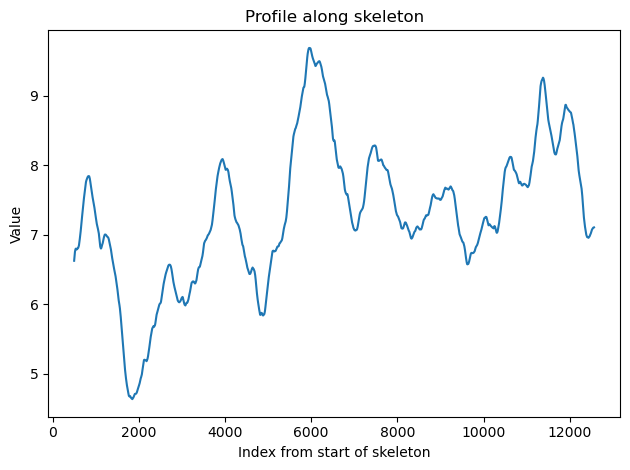

In [25]:
w = 1000  # set your desired window width
y_avg = np.convolve(y, np.ones(w)/w, mode='valid')

plt.figure()
plt.plot(x[500:-499], y_avg)
plt.xlabel('Index from start of skeleton')   # or 'Arc length (px)' if use_arc_length=True
plt.ylabel('Value')
plt.title('Profile along skeleton')
plt.tight_layout()
plt.show()